# 04 · Final Figures
**Project 1: Rossmann Store Sales Prediction**

Five figures that tell the story of the project, built to be readable on their own:
a title, labeled axes, annotations, a colorblind-friendly palette, and the source noted on each figure.
They are saved to `outputs/figures/`.

> Run notebook `03_modeling.ipynb` first: Figure 3 reads the backtest results it saves.

## Project setup

In [1]:
import sys
from pathlib import Path

# Project folders (works from notebooks/ or from the repo root)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
DATA = ROOT / "data"
OUT = ROOT / "outputs"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

## Imports and plot style

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from xgboost import XGBRegressor

from features import add_date_features, add_lag_features, merge_store_info
from modeling import make_model, INPUT_COLUMNS

In [3]:
plt.style.use("seaborn-v0_8-darkgrid")
plt.rcParams.update({
    "figure.figsize": (11, 5.5), "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 11, "axes.titlesize": 15, "axes.titleweight": "bold", "axes.labelsize": 12,
    "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10,
})
# Okabe-Ito colors (readable for color-blind viewers)
COLORS = {"plain": "#7F7F7F", "linear": "#E69F00", "xgb": "#0072B2", "xgb_log": "#009E73", "accent": "#D55E00"}
SOURCE = "Source: Rossmann Store Sales (Kaggle). Open store-days only."

def add_source(fig, text=SOURCE):
    fig.text(0.01, -0.01, text, fontsize=8.5, color="#555555", ha="left", va="top")

print("Style:", plt.rcParams["axes.facecolor"], "| figures go to:", FIG.relative_to(ROOT))

Style: #EAEAF2 | figures go to: outputs/figures


In [4]:
BASE = "https://raw.githubusercontent.com/RPI-DATA/tutorials-intro/master/rossmann-store-sales/rossmann-store-sales/"

def load(name):
    local = DATA / name
    return pd.read_csv(local if local.exists() else BASE + name, low_memory=False)

train = load("train.csv")
store = load("store.csv")
train["Date"] = pd.to_datetime(train["Date"])
train = train.sort_values(["Store", "Date"]).reset_index(drop=True)

open_days = train[(train["Open"] == 1) & (train["Sales"] > 0)]
print("Open store-days:", len(open_days))

Open store-days: 844338


## Figure 1: Sales over time (and a dip that is not a demand story)

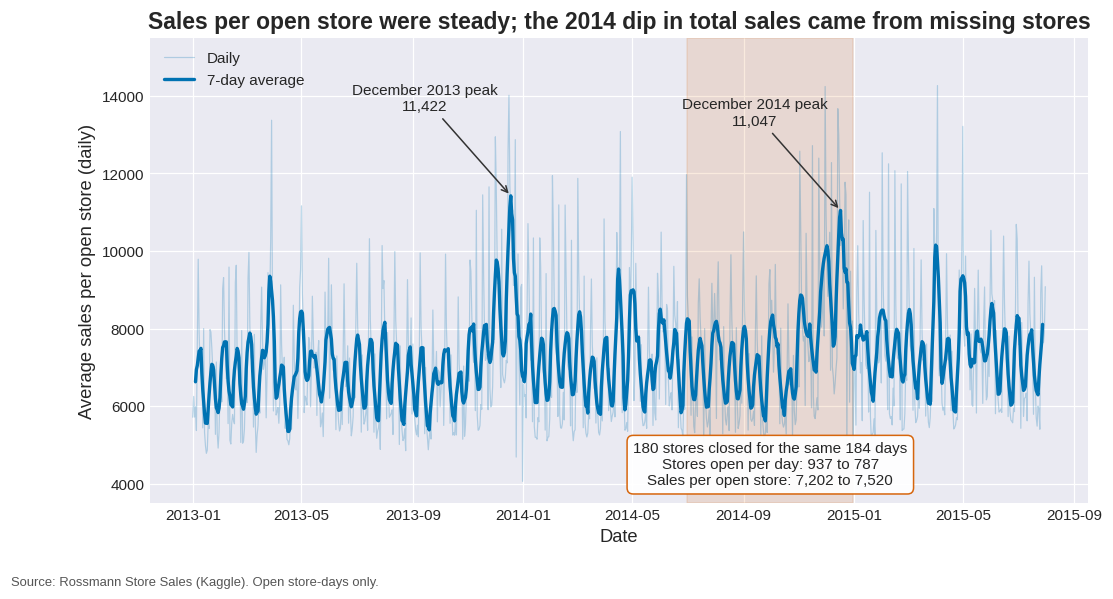

Stores with no rows from 2014-07-01 to 2014-12-31: 180
Jul-Dec 2013 vs 2014, stores open per day: 937 -> 787
Jul-Dec 2013 vs 2014, sales per open store: 7,202 -> 7,520


In [5]:
daily = open_days.groupby("Date").agg(per_store=("Sales", "mean"), stores_open=("Store", "nunique"))
smooth = daily["per_store"].rolling(7, center=True).mean()

gap_start, gap_end = pd.Timestamp("2014-07-01"), pd.Timestamp("2014-12-31")
missing_stores = train["Store"].nunique() - train[train["Date"].between(gap_start, gap_end)]["Store"].nunique()

def half_year(year):
    m = (daily.index >= f"{year}-07-01") & (daily.index <= f"{year}-12-31")
    return daily.loc[m, "per_store"].mean(), daily.loc[m, "stores_open"].mean()

(s13, n13), (s14, n14) = half_year(2013), half_year(2014)

fig, ax = plt.subplots()
ax.plot(daily.index, daily["per_store"], color=COLORS["xgb"], alpha=0.25, linewidth=0.8, label="Daily")
ax.plot(smooth.index, smooth, color=COLORS["xgb"], linewidth=2.2, label="7-day average")
ax.axvspan(gap_start, gap_end, color=COLORS["accent"], alpha=0.13)

for year in (2013, 2014):
    dec = smooth[(smooth.index >= f"{year}-12-01") & (smooth.index <= f"{year}-12-31")]
    peak_day = dec.idxmax()
    ax.annotate(f"December {year} peak\n{dec.max():,.0f}", xy=(peak_day, dec.max()),
                xytext=(peak_day - pd.Timedelta(days=95), dec.max() + 2200),
                arrowprops=dict(arrowstyle="->", color="#333333"), fontsize=10, ha="center")

ax.text(gap_start + (gap_end - gap_start) / 2, 3900,
        f"{missing_stores} stores closed for the same {len(pd.date_range(gap_start, gap_end))} days\n"
        f"Stores open per day: {n13:,.0f} to {n14:,.0f}\n"
        f"Sales per open store: {s13:,.0f} to {s14:,.0f}",
        ha="center", va="bottom", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor=COLORS["accent"], alpha=0.95))

ax.set_ylim(3500, 15500)
ax.set_title("Sales per open store were steady; the 2014 dip in total sales came from missing stores")
ax.set_xlabel("Date")
ax.set_ylabel("Average sales per open store (daily)")
ax.legend(loc="upper left")
add_source(fig)
plt.savefig(FIG / "fig1_sales_over_time.png")
plt.show()

print(f"Stores with no rows from {gap_start.date()} to {gap_end.date()}: {missing_stores}")
print(f"Jul-Dec 2013 vs 2014, stores open per day: {n13:.0f} -> {n14:.0f}")
print(f"Jul-Dec 2013 vs 2014, sales per open store: {s13:,.0f} -> {s14:,.0f}")

## Figure 2: Promotions by weekday

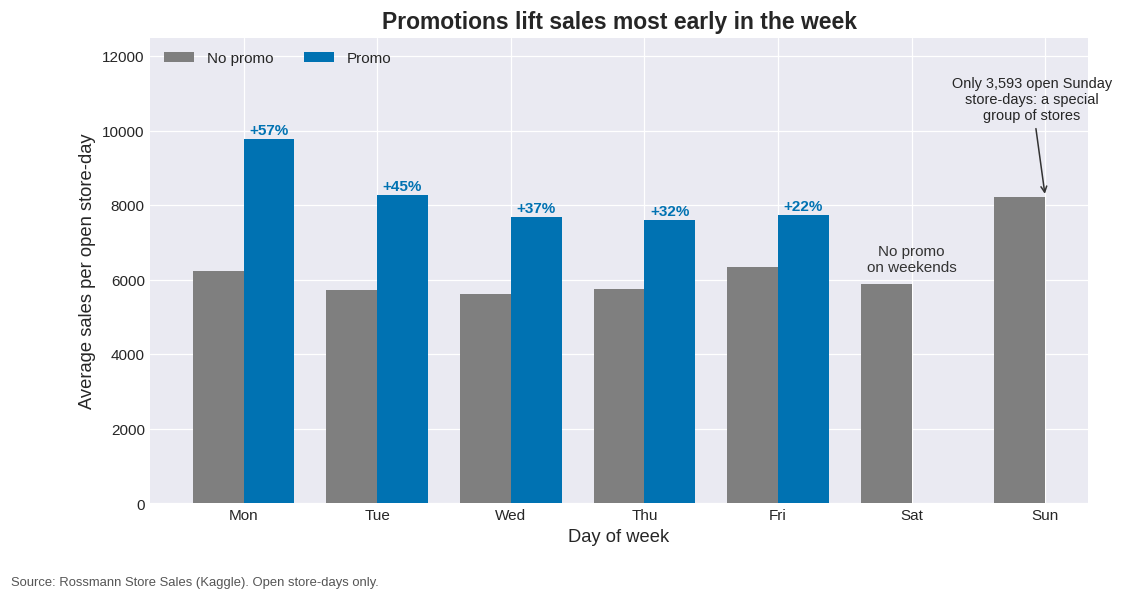

Promo uplift by weekday:
DayOfWeek
Mon    57.1
Tue    44.8
Wed    36.8
Thu    32.1
Fri    22.1


In [6]:
by = open_days.groupby(["DayOfWeek", "Promo"])["Sales"].mean().unstack()
counts = open_days.groupby("DayOfWeek").size()
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
uplift = (by[1] / by[0] - 1) * 100

x = np.arange(7)
w = 0.38
fig, ax = plt.subplots()
ax.bar(x - w / 2, by[0], w, color=COLORS["plain"], label="No promo")
ax.bar(x[:5] + w / 2, by[1].iloc[:5], w, color=COLORS["xgb"], label="Promo")
for i in range(5):
    ax.text(x[i] + w / 2, by[1].iloc[i] + 120, f"+{uplift.iloc[i]:.0f}%", ha="center", fontsize=10,
            color=COLORS["xgb"], fontweight="bold")
ax.text(5, by[0].iloc[5] + 350, "No promo\non weekends", ha="center", fontsize=10, color="#333333")
ax.annotate(f"Only {counts.loc[7]:,} open Sunday\nstore-days: a special\ngroup of stores",
            xy=(6, by[0].iloc[6]), xytext=(5.9, 10300), ha="center", fontsize=9.5,
            arrowprops=dict(arrowstyle="->", color="#333333"))
ax.set_xticks(x)
ax.set_xticklabels(days)
ax.set_ylim(0, 12500)
ax.set_title("Promotions lift sales most early in the week")
ax.set_xlabel("Day of week")
ax.set_ylabel("Average sales per open store-day")
ax.legend(loc="upper left", ncol=2)
add_source(fig)
plt.savefig(FIG / "fig2_promo_by_weekday.png")
plt.show()

print("Promo uplift by weekday:")
print(uplift.round(1).dropna().rename(index=dict(zip(range(1, 8), days))).to_string())

## Figure 3: How do the models compare?

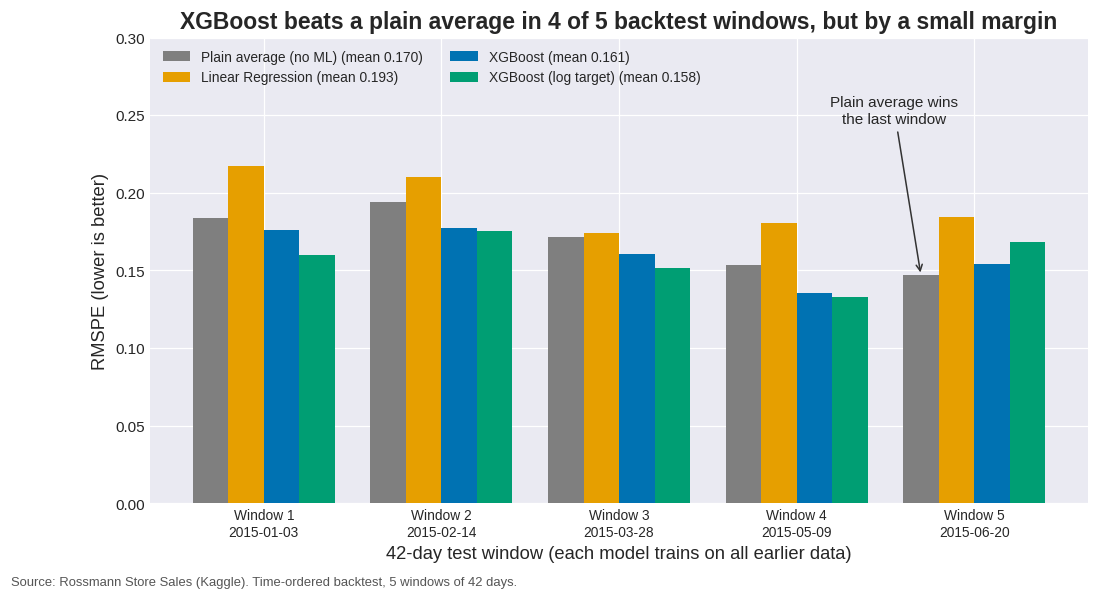

Mean RMSPE over the 5 windows:
Plain average (no ML)    0.170 +/- 0.020
Linear Regression        0.193 +/- 0.019
XGBoost                  0.161 +/- 0.017
XGBoost (log target)     0.158 +/- 0.016
XGBoost beats the plain average in 4 of 5 windows (windows [1, 2, 3, 4] )


In [7]:
results = pd.read_csv(OUT / "results" / "backtest_metrics.csv")
table = results.pivot(index="fold", columns="model", values="rmspe")
starts = results.drop_duplicates("fold").set_index("fold")["window_start"]

names = {
    "Store+weekday+promo average": ("Plain average (no ML)", COLORS["plain"]),
    "Linear Regression": ("Linear Regression", COLORS["linear"]),
    "XGBoost (200 trees)": ("XGBoost", COLORS["xgb"]),
    "XGBoost (200 trees, log target)": ("XGBoost (log target)", COLORS["xgb_log"]),
}
plain = table["Store+weekday+promo average"]
wins = int((table["XGBoost (200 trees)"] < plain).sum())

fig, ax = plt.subplots()
width = 0.2
folds = np.arange(1, 6)
for i, (col, (label, color)) in enumerate(names.items()):
    ax.bar(folds + (i - 1.5) * width, table[col], width, color=color,
           label=f"{label} (mean {table[col].mean():.3f})")
ax.annotate("Plain average wins\nthe last window", xy=(5 - 1.5 * width, plain.loc[5]), xytext=(4.55, 0.245),
            ha="center", fontsize=10, arrowprops=dict(arrowstyle="->", color="#333333"))
ax.set_xticks(folds)
ax.set_xticklabels([f"Window {i}\n{starts.loc[i]}" for i in folds], fontsize=9)
ax.set_ylim(0, 0.30)
ax.set_title(f"XGBoost beats a plain average in {wins} of 5 backtest windows, but by a small margin")
ax.set_xlabel("42-day test window (each model trains on all earlier data)")
ax.set_ylabel("RMSPE (lower is better)")
ax.legend(loc="upper left", ncol=2, fontsize=9)
add_source(fig, "Source: Rossmann Store Sales (Kaggle). Time-ordered backtest, 5 windows of 42 days.")
plt.savefig(FIG / "fig3_model_comparison.png")
plt.show()

print("Mean RMSPE over the 5 windows:")
for col, (label, _) in names.items():
    print(f"{label:24s} {table[col].mean():.3f} +/- {table[col].std():.3f}")
print("XGBoost beats the plain average in", wins, "of 5 windows (windows", list(table.index[table["XGBoost (200 trees)"] < plain]), ")")

## Figures 4 and 5: Predictions on the last 42 days

In [8]:
feat = add_date_features(train)
feat = add_lag_features(feat, lags=(42, 49))
feat = merge_store_info(feat, store)
feat["state_holiday"] = feat["state_holiday"].astype(str)
data = feat[(feat["Open"] == 1) & (feat["Sales"] > 0)].reset_index(drop=True)

X, y = data[INPUT_COLUMNS], data["Sales"]
test_start = data["Date"].max() - pd.Timedelta(days=41)
is_train = (data["Date"] < test_start).to_numpy()
is_test = ~is_train & (data["Date"] >= test_start).to_numpy()

model = make_model(XGBRegressor(n_estimators=200, random_state=42), log_target=True)
model.fit(X[is_train], y[is_train])
pred = model.predict(X[is_test])
actual = y[is_test].to_numpy()
test_dates = data.loc[is_test, "Date"].to_numpy()
print("Test window:", pd.Timestamp(test_start).date(), "to", data["Date"].max().date(), "| rows:", int(is_test.sum()))

Test window: 2015-06-20 to 2015-07-31 | rows: 40282


### Figure 4: Actual vs predicted

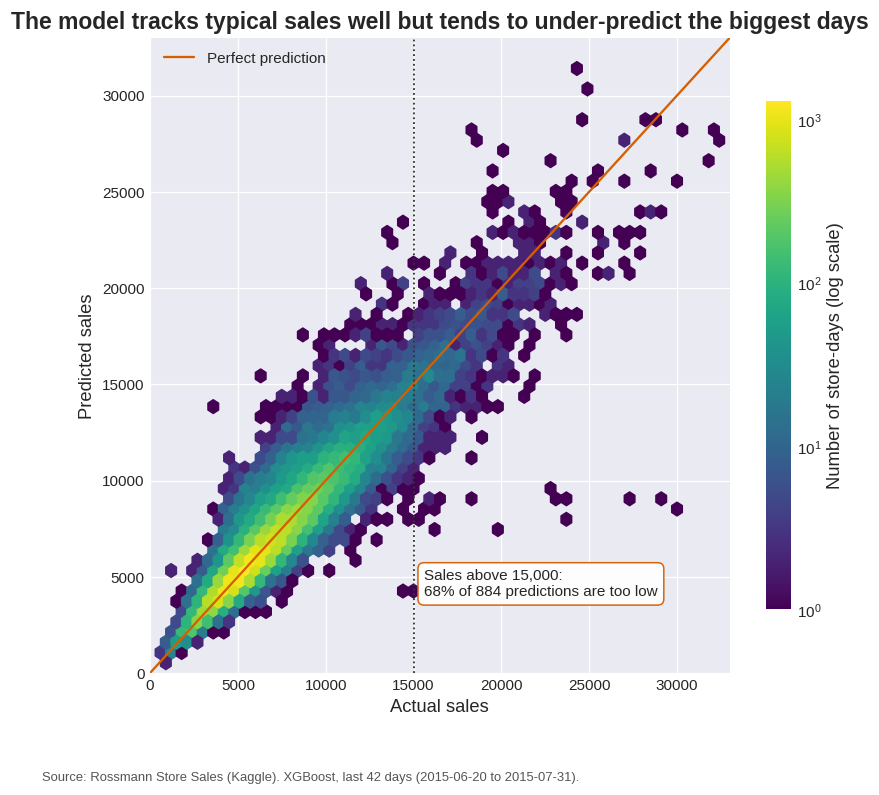

Rows with actual sales above 15,000: 884
Share of those predicted below the actual: 68%
Median predicted / actual for those rows: 0.95


In [9]:
big = actual > 15000
below = (pred[big] < actual[big]).mean()

fig, ax = plt.subplots(figsize=(8.5, 7.5))
hb = ax.hexbin(actual, pred, gridsize=55, bins="log", cmap="viridis", mincnt=1, extent=(0, 33000, 0, 33000))
ax.plot([0, 33000], [0, 33000], color=COLORS["accent"], linewidth=1.5, label="Perfect prediction")
ax.axvline(15000, color="#333333", linestyle=":", linewidth=1.2)
ax.annotate(f"Sales above 15,000:\n{below:.0%} of {int(big.sum()):,} predictions are too low",
            xy=(15000, 4500), xytext=(15600, 4000), fontsize=10, ha="left",
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor=COLORS["accent"], alpha=0.95))
ax.set_xlim(0, 33000)
ax.set_ylim(0, 33000)
ax.set_title("The model tracks typical sales well but tends to under-predict the biggest days")
ax.set_xlabel("Actual sales")
ax.set_ylabel("Predicted sales")
ax.legend(loc="upper left")
fig.colorbar(hb, ax=ax, label="Number of store-days (log scale)", shrink=0.8)
add_source(fig, "Source: Rossmann Store Sales (Kaggle). XGBoost, last 42 days (2015-06-20 to 2015-07-31).")
plt.savefig(FIG / "fig4_actual_vs_predicted.png")
plt.show()

print(f"Rows with actual sales above 15,000: {int(big.sum()):,}")
print(f"Share of those predicted below the actual: {below:.0%}")
print(f"Median predicted / actual for those rows: {np.median(pred[big] / actual[big]):.2f}")

### Figure 5: Where do the errors happen?

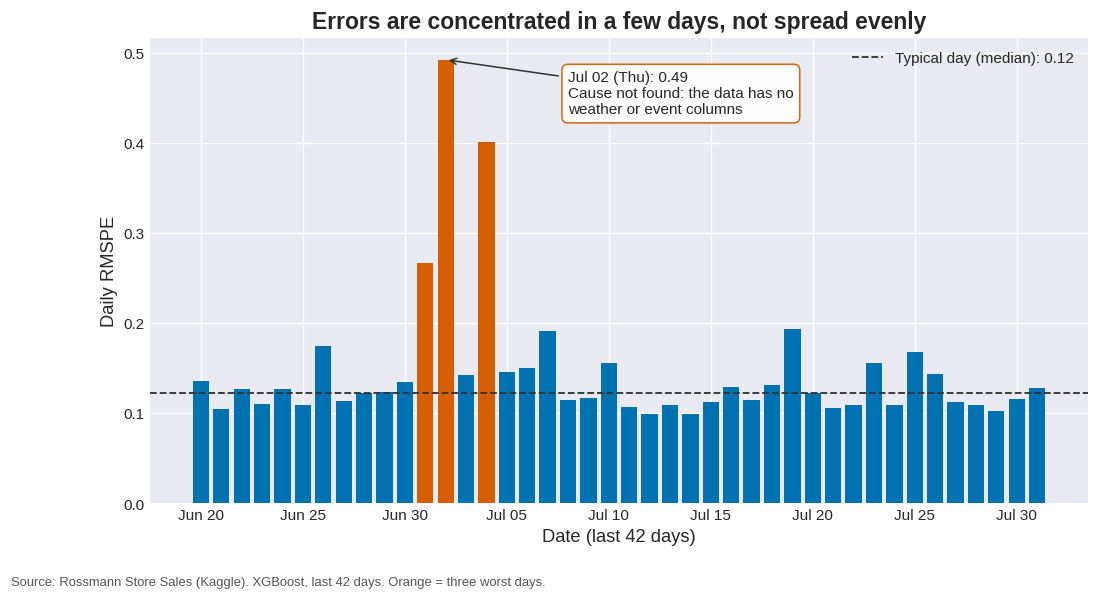

2015-07-02 Thu RMSPE 0.492
2015-07-04 Sat RMSPE 0.401
2015-07-01 Wed RMSPE 0.267
Typical day RMSPE (median over days): 0.123


In [10]:
pct_sq = ((actual - pred) / actual) ** 2
by_date = pd.Series(pct_sq).groupby(test_dates).mean().pow(0.5)
typical = by_date.median()
worst = by_date.nlargest(3)

fig, ax = plt.subplots()
colors = [COLORS["accent"] if d in worst.index else COLORS["xgb"] for d in by_date.index]
ax.bar(by_date.index, by_date.values, color=colors, width=0.8)
ax.axhline(typical, color="#333333", linestyle="--", linewidth=1.2, label=f"Typical day (median): {typical:.2f}")
ax.legend(loc="upper right")
top = worst.index[0]
ax.annotate(f"{pd.Timestamp(top).strftime('%b %d')} ({pd.Timestamp(top).day_name()[:3]}): {worst.iloc[0]:.2f}\n"
            "Cause not found: the data has no\nweather or event columns",
            xy=(top, worst.iloc[0]), xytext=(pd.Timestamp(top) + pd.Timedelta(days=6), worst.iloc[0] - 0.06),
            fontsize=10, arrowprops=dict(arrowstyle="->", color="#333333"),
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor=COLORS["accent"], alpha=0.95))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=5))
ax.set_title("Errors are concentrated in a few days, not spread evenly")
ax.set_xlabel("Date (last 42 days)")
ax.set_ylabel("Daily RMSPE")
add_source(fig, "Source: Rossmann Store Sales (Kaggle). XGBoost, last 42 days. Orange = three worst days.")
plt.savefig(FIG / "fig5_daily_error.png")
plt.show()

for date, value in worst.items():
    print(pd.Timestamp(date).date(), pd.Timestamp(date).day_name()[:3], "RMSPE", round(value, 3))
print("Typical day RMSPE (median over days):", round(typical, 3))

In [11]:
print("Saved figures:")
for path in sorted(FIG.glob("fig*.png")):
    print(" ", path.relative_to(ROOT))

Saved figures:
  outputs/figures/fig1_sales_over_time.png
  outputs/figures/fig2_promo_by_weekday.png
  outputs/figures/fig3_model_comparison.png
  outputs/figures/fig4_actual_vs_predicted.png
  outputs/figures/fig5_daily_error.png


## Summary
- Five figures: sales over time, promo by weekday, model comparison, actual vs predicted, daily error
- Each one has a takeaway title, labeled axes, annotations computed from the data, and a source line
- The model comparison (Figure 3) is the headline: XGBoost is only modestly better than a plain average